# Where NFL Camps Are Breaking Down

Stacked bars of the 2026 preseason injury report, split by body part and
availability status, with knee injuries broken out by sub-type.

**Source:** `data/raw/nfl_injuries_2026-08-24.json` — ESPN via the NFL MCP server,
captured Aug 24 2026 (421 raw records).

The figure is built up one cell at a time. Each drawing cell ends with `fig`, so
re-running it shows the chart as it stands at that step.

> **Note:** the drawing cells mutate a single `fig`/`ax`. If you tweak something,
> re-run from *Step 5: start the figure* rather than replaying a cell in place —
> otherwise you'll draw the bars twice on top of each other.

## Step 1 — Imports and the house style

`STYLE_FILE` and `RAW_DATA_DIR` come from `nfl_injuries/config.py` so the paths
resolve the same whether this runs from `notebooks/` or the project root.

In [1]:
import collections
import json

import matplotlib.pyplot as plt
import pandas as pd

from dataglazer_nfl.config import FIGURES_DIR, RAW_DATA_DIR
from dataglazer_nfl.viz.style import apply_style

apply_style()

# the layout below is hand-tuned with subplots_adjust, so don't let
# savefig re-crop it on the way out
plt.rcParams["savefig.bbox"] = "standard"

print(plt.rcParams["font.sans-serif"][:2], "|", plt.rcParams["figure.facecolor"])

['Baloo 2', 'Poppins'] | #1F2831


## Step 2 — Chart constants

Four availability statuses, drawn bottom-to-top in severity order. Anything whose
designation describes *availability* rather than an *injury* gets dropped.

In [2]:
SRC = RAW_DATA_DIR / "nfl_injuries_2026-08-24.json"
TOP_N = 14

# designations that aren't really injuries
NON_INJURY = {"Undisclosed", "Suspension", "Personal", "Illness"}

STATUS_ORDER = ["Injured Reserve", "Out", "Doubtful", "Questionable"]
STATUS_COLOR = {
    "Injured Reserve": "#FF4444",  # red   — most severe, sits at the bottom
    "Out": "#FF8C00",  # orange
    "Doubtful": "#FFD700",  # gold
    "Questionable": "#00E5FF",  # cyan  — least severe, on top
}

# knee sub-types get their own columns, indented under the combined bar
KNEE_SUBS = [
    ("__UNSPEC__", "\u00b7 unspecified"),
    ("Knee - ACL", "\u00b7 ACL"),
    ("Knee - MCL", "\u00b7 MCL"),
    ("Knee - ACL + MCL", "\u00b7 ACL+MCL"),
    ("Knee - PCL", "\u00b7 PCL"),
    ("Knee - Meniscus", "\u00b7 Meniscus"),
]

## Step 3 — Load and filter

ESPN reports knee injuries at two levels of detail — plain `"Knee"` and specific
`"Knee - ACL"`. `base()` collapses the second form onto the first so both roll up
into one bucket; the raw `injury_type` is kept intact for the sub-type columns.

In [3]:
def base(injury_type):
    """Collapse 'Knee - ACL' and friends down to 'Knee'."""
    return (injury_type or "Undisclosed").split(" - ")[0].strip()


with open(SRC) as f:
    payload = json.load(f)

records = [
    r
    for r in payload["records"]
    if base(r.get("injury_type")) not in NON_INJURY and r.get("status") in STATUS_COLOR
]

print(f"{payload['n_records']} raw -> {len(records)} charted")

421 raw -> 299 charted


### What's actually in there

A look at the distribution before committing to a layout — this is what motivates
giving knees their own breakout.

In [4]:
pd.Series(collections.Counter(base(r["injury_type"]) for r in records)).sort_values(
    ascending=False
).head(15)

Knee          80
Hamstring     28
Ankle         26
Groin         20
Concussion    13
Shoulder      12
Achilles      12
Leg           11
Quadriceps    11
Calf          11
Back          10
Neck           9
Foot           8
Pectoral       6
Hip            6
dtype: int64

In [5]:
pd.Series(collections.Counter(r["status"] for r in records))[STATUS_ORDER]

Injured Reserve     50
Out                 41
Doubtful             4
Questionable       204
dtype: int64

## Step 4 — Build the column spec

Each column is `(label, predicate, is_breakout)`. The predicate decides which
records land in that column; `is_breakout` marks the knee sub-types, which are
*subsets* of the combined bar rather than new columns of players.

The `v=t` default argument binds the loop variable at definition time — without
it every lambda would close over the *final* value of `t` and all the columns
would count the same injury.

In [6]:
cols = [("Knee (combined)", lambda r: base(r["injury_type"]) == "Knee", False)]

for raw, label in KNEE_SUBS:
    v = "Knee" if raw == "__UNSPEC__" else raw
    cols.append((label, lambda r, q=v: r["injury_type"] == q, True))

totals = collections.Counter(base(r["injury_type"]) for r in records)
for t, _ in totals.most_common(TOP_N):
    if t != "Knee":
        cols.append((t, lambda r, v=t: base(r["injury_type"]) == v, False))

labels = [c[0] for c in cols]
is_sub = [c[2] for c in cols]

print(f"{len(cols)} columns")
labels

20 columns


['Knee (combined)',
 '· unspecified',
 '· ACL',
 '· MCL',
 '· ACL+MCL',
 '· PCL',
 '· Meniscus',
 'Hamstring',
 'Ankle',
 'Groin',
 'Concussion',
 'Achilles',
 'Shoulder',
 'Leg',
 'Calf',
 'Quadriceps',
 'Back',
 'Neck',
 'Foot',
 'Hip']

### Count each column by status

`counts[status]` is one row of bar heights, in column order. The DataFrame is
just for eyeballing it — the plotting code below works off the lists.

In [7]:
counts = {
    s: [sum(1 for r in records if pred(r) and r["status"] == s) for _, pred, _ in cols]
    for s in STATUS_ORDER
}

frame = pd.DataFrame(counts, index=labels)
frame["TOTAL"] = frame.sum(axis=1)
frame

,Injured Reserve,Out,Doubtful,Questionable,TOTAL
Knee (combined),25,16,2,37,80
· unspecified,12,8,2,26,48
· ACL,9,7,0,6,22
· MCL,1,0,0,3,4
· ACL+MCL,1,1,0,1,3
· PCL,1,0,0,1,2
· Meniscus,1,0,0,0,1
Hamstring,0,0,1,27,28
Ankle,2,3,0,21,26
Groin,2,0,0,18,20


## Step 5 — Start the figure

13.5 x 10.8in at 100 dpi -> 1350 x 1080px. The `subplots_adjust` call reserves
the top ~15% for the title block and the bottom ~25% for rotated tick labels plus
the footnote, which is why `savefig.bbox` had to be set to `standard`.

**Re-run from here** if you change anything below.

Matplotlib is building the font cache; this may take a moment.


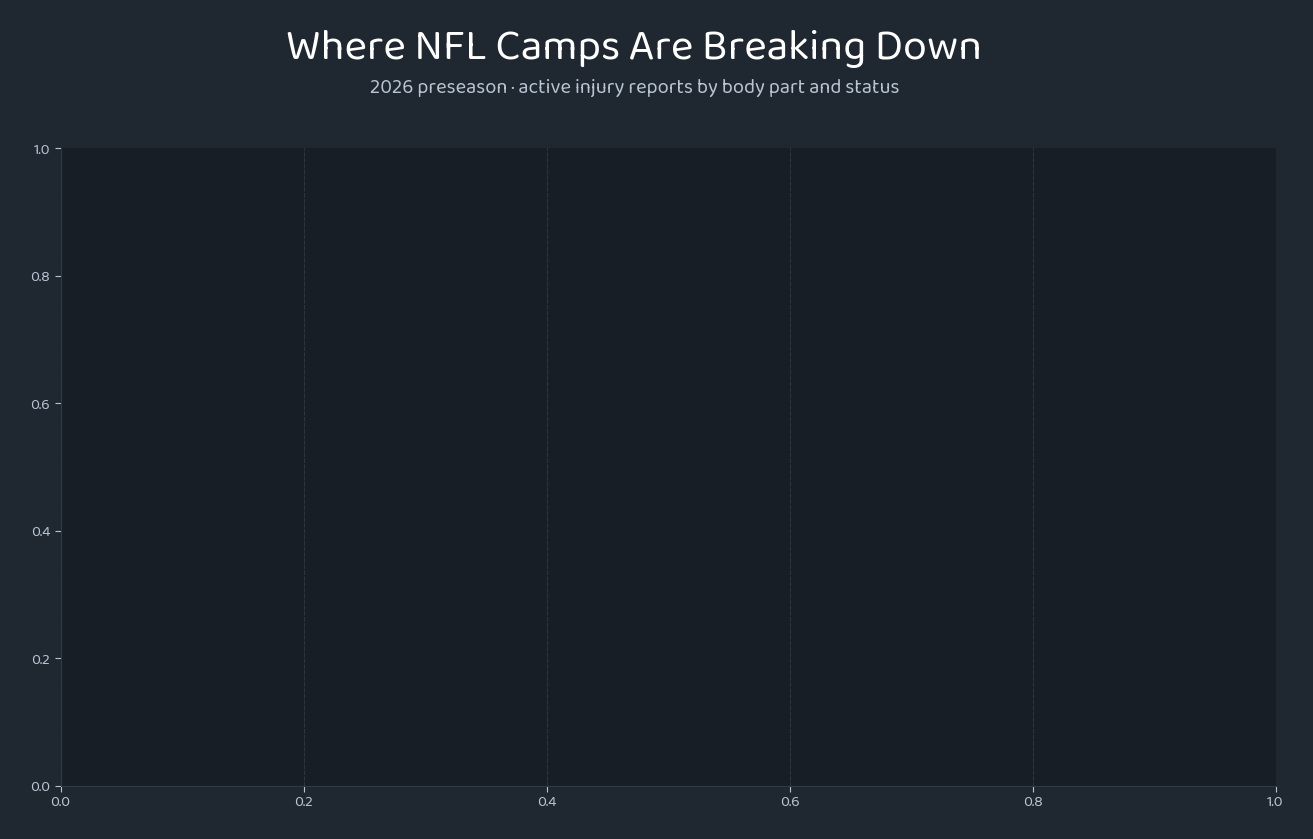

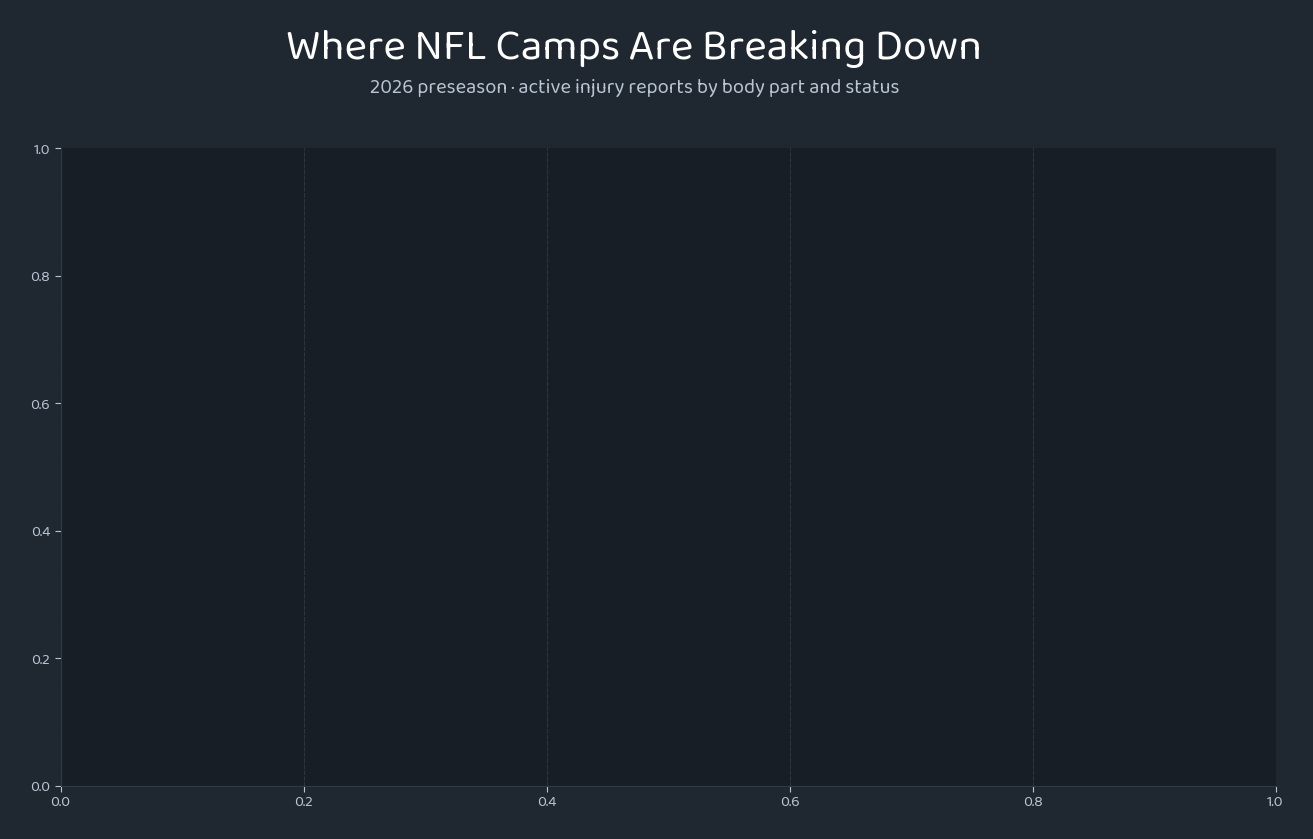

In [8]:
fig, ax = plt.subplots(figsize=(13.5, 10.8))
fig.subplots_adjust(left=0.075, right=0.975, top=0.845, bottom=0.255)

fig.text(
    0.5,
    0.955,
    "Where NFL Camps Are Breaking Down",
    ha="center",
    va="top",
    fontsize=31,
    fontweight="bold",
    color="#FFFFFF",
)
fig.text(
    0.5,
    0.910,
    "2026 preseason \u00b7 active injury reports by body part and status",
    ha="center",
    va="top",
    fontsize=14.5,
    color="#B7C4D2",
)

fig

## Step 6 — Stack the bars

One `ax.bar` call per status, each starting where the previous one ended.
Segments of 3+ get their count printed inside; anything smaller has no room for
legible text.

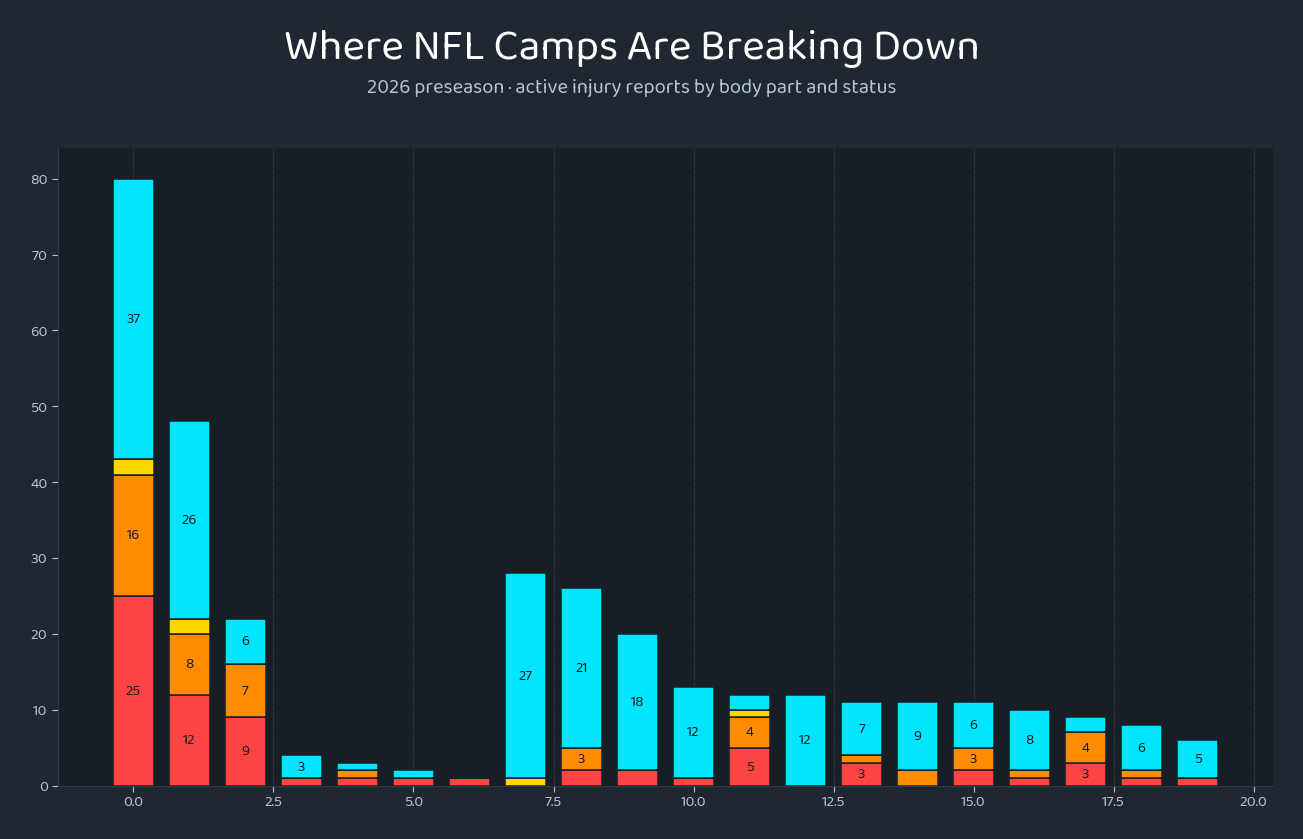

In [9]:
x = range(len(cols))
bottom = [0] * len(cols)

for status in STATUS_ORDER:
    vals = counts[status]
    ax.bar(
        x,
        vals,
        bottom=bottom,
        width=0.72,
        label=status,
        color=[STATUS_COLOR[status]] * len(cols),
        alpha=1.0,
        edgecolor="#171E25",
        linewidth=1.1,
        zorder=3,
    )

    # in-bar count, only where the segment is tall enough to read
    for i, v in enumerate(vals):
        if v >= 3:
            ax.text(
                i,
                bottom[i] + v / 2,
                str(v),
                ha="center",
                va="center",
                fontsize=10.5,
                fontweight="bold",
                color="#171E25",
                zorder=4,
            )

    bottom = [b + v for b, v in zip(bottom, vals)]

fig

## Step 7 — Mark the breakouts

The knee sub-type columns are hatched and sit inside a faint cyan band, so they
read as a decomposition of the first bar instead of six more body parts. Without
this the chart implies ~80 extra injured players who don't exist.

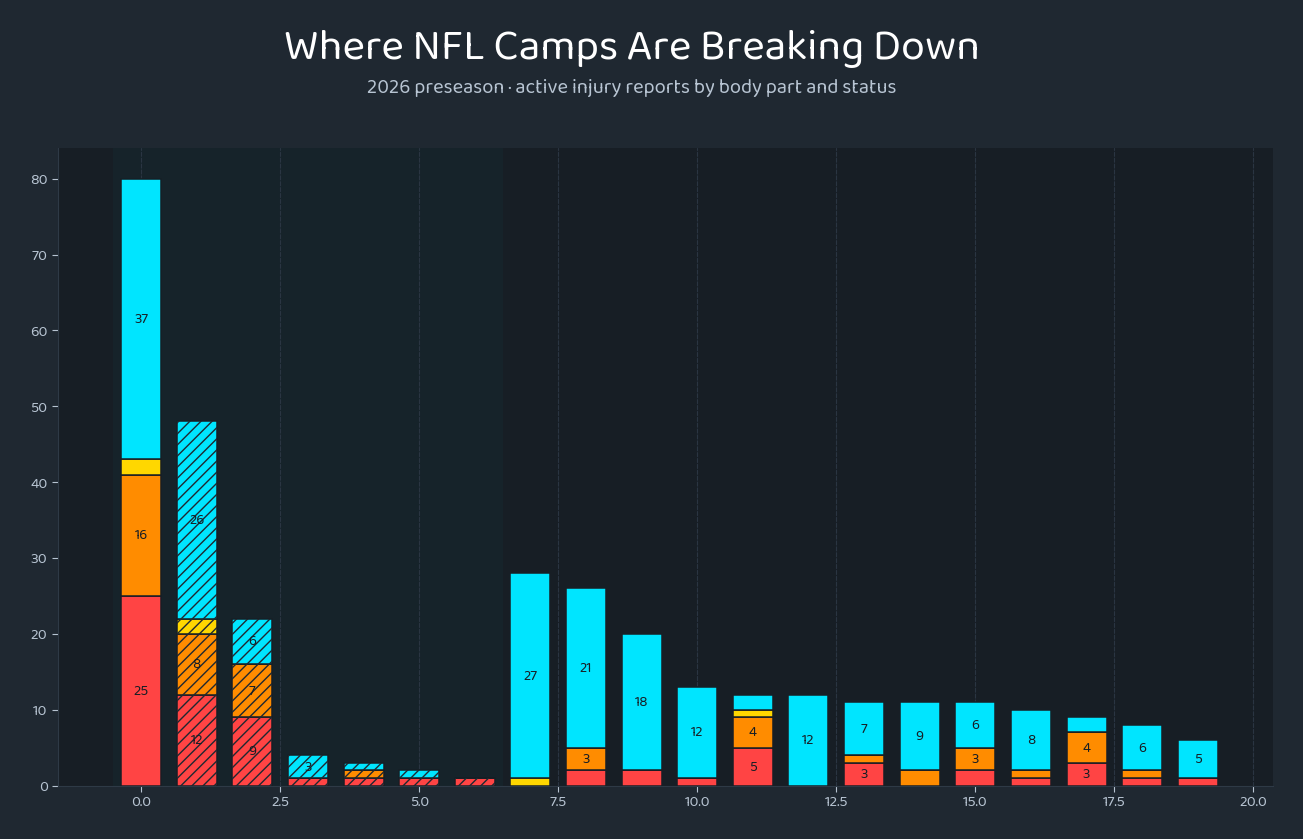

In [10]:
for i, sub in enumerate(is_sub):
    if sub:
        ax.bar(
            i,
            bottom[i],
            width=0.72,
            fill=False,
            edgecolor="#1F2831",
            linewidth=0,
            hatch="///",
            zorder=3.5,
        )

ax.axvspan(-0.5, len(KNEE_SUBS) + 0.5, color="#00E5FF", alpha=0.028, zorder=0)

fig

## Step 8 — Column totals

Dimmed on the breakout columns, bright white on the real ones — same visual hint
as the hatching, reinforced.

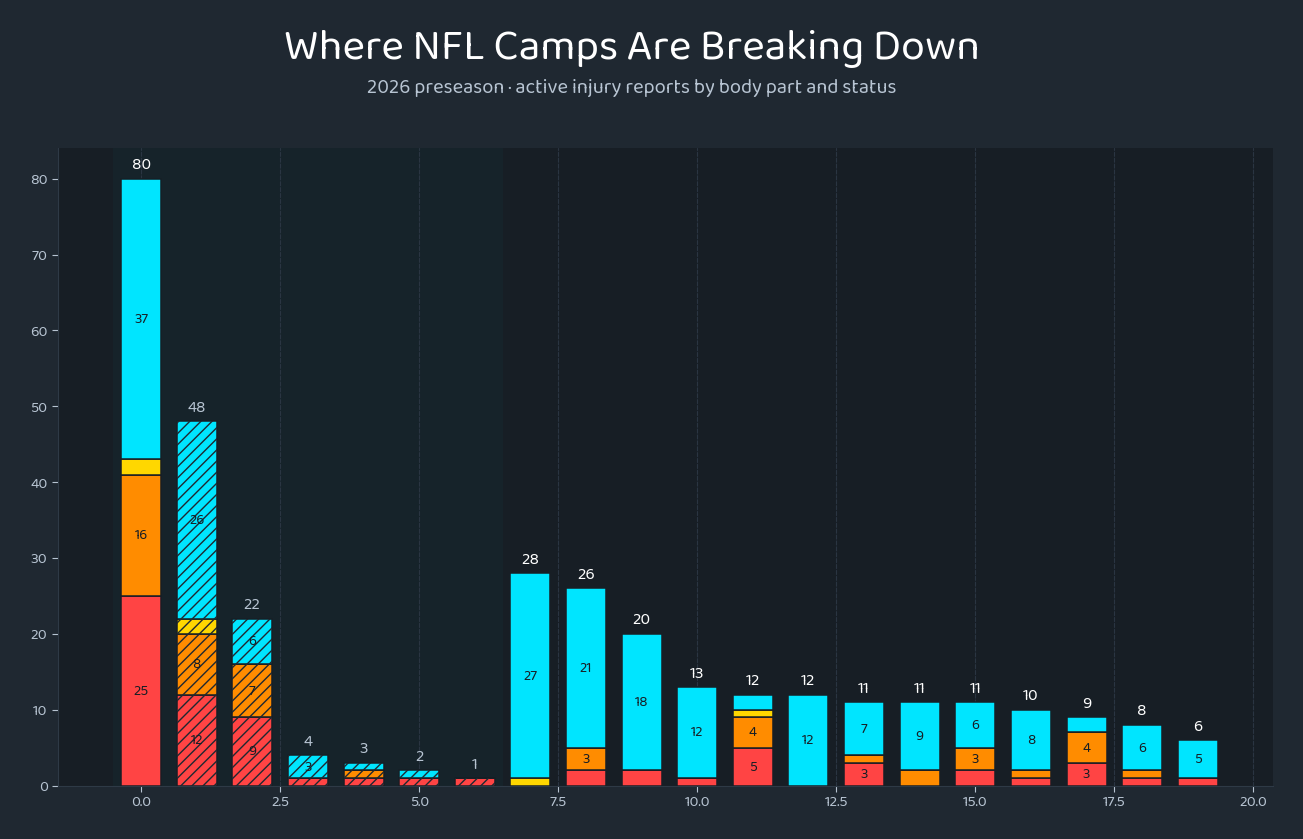

In [11]:
for i, total in enumerate(bottom):
    ax.text(
        i,
        total + 0.9,
        str(total),
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold",
        color="#B7C4D2" if is_sub[i] else "#FFFFFF",
        zorder=4,
    )

fig

## Step 9 — Axes, grid and legend

The stylesheet grids on the x-axis by default, which is wrong for vertical bars —
flipped here. Tick labels are tinted to match the breakout/real split.

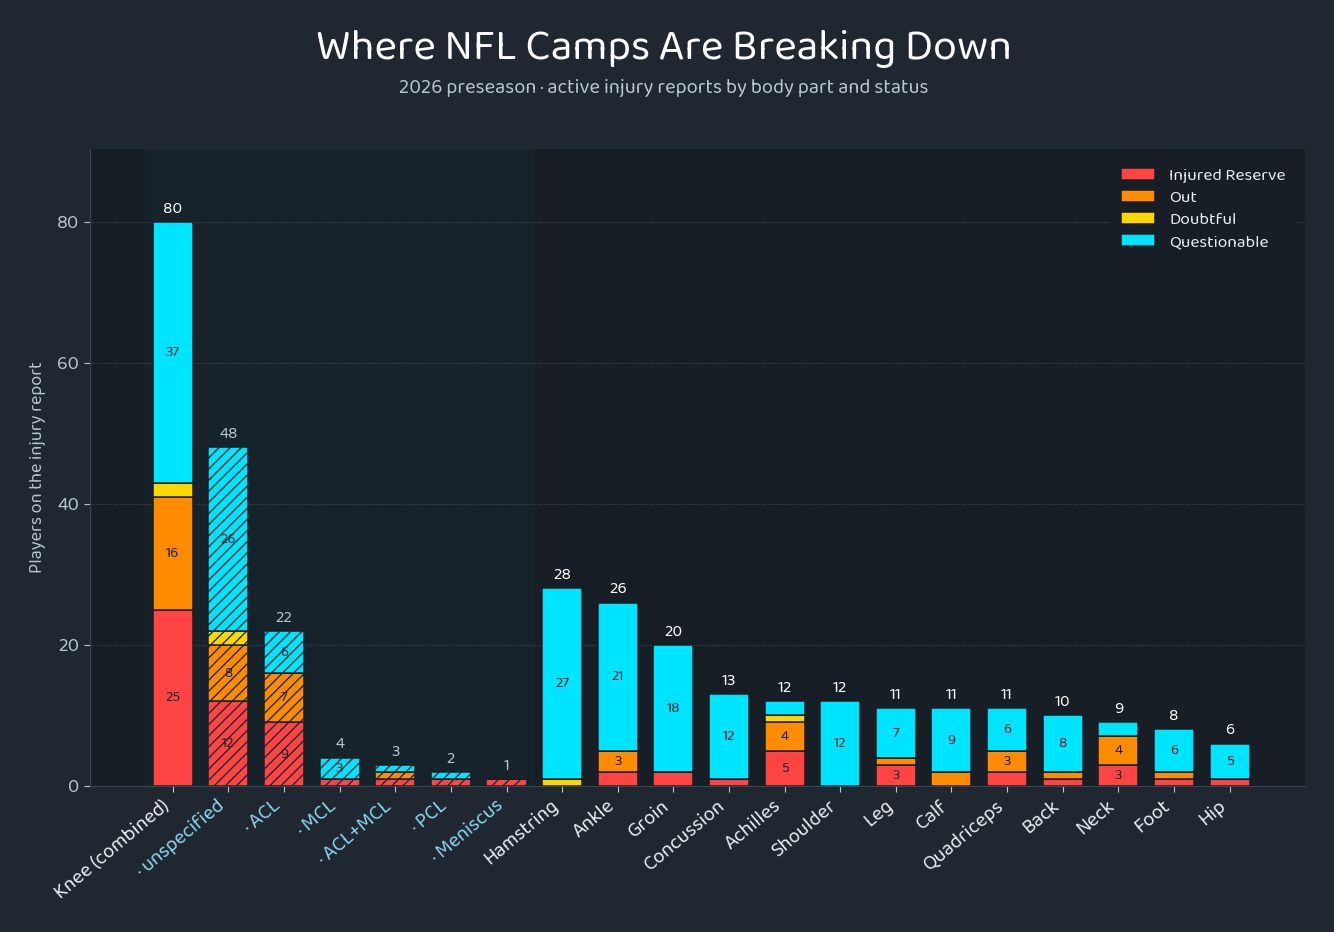

In [12]:
ax.set_xticks(list(x))
ax.set_xticklabels(labels, rotation=40, ha="right", fontsize=14.5)
for tick, sub in zip(ax.get_xticklabels(), is_sub):
    tick.set_color("#8FD4EE" if sub else "#E6EDF3")

ax.set_ylabel("Players on the injury report", color="#B7C4D2", fontsize=13)
ax.set_ylim(0, max(bottom) * 1.13)  # headroom for the total labels
ax.tick_params(axis="y", labelsize=14)

ax.grid(axis="y", visible=True)
ax.grid(axis="x", visible=False)
for s in ("left", "bottom"):
    ax.spines[s].set_color("#3A4854")

leg = ax.legend(
    loc="upper right",
    fontsize=12.5,
    frameon=True,
    facecolor="#171E25",
    edgecolor="#3A4854",
    labelcolor="#E6EDF3",
)
leg.set_zorder(5)

fig

## Step 10 — Footnote

Says out loud what the hatching implies, and states the exclusions.

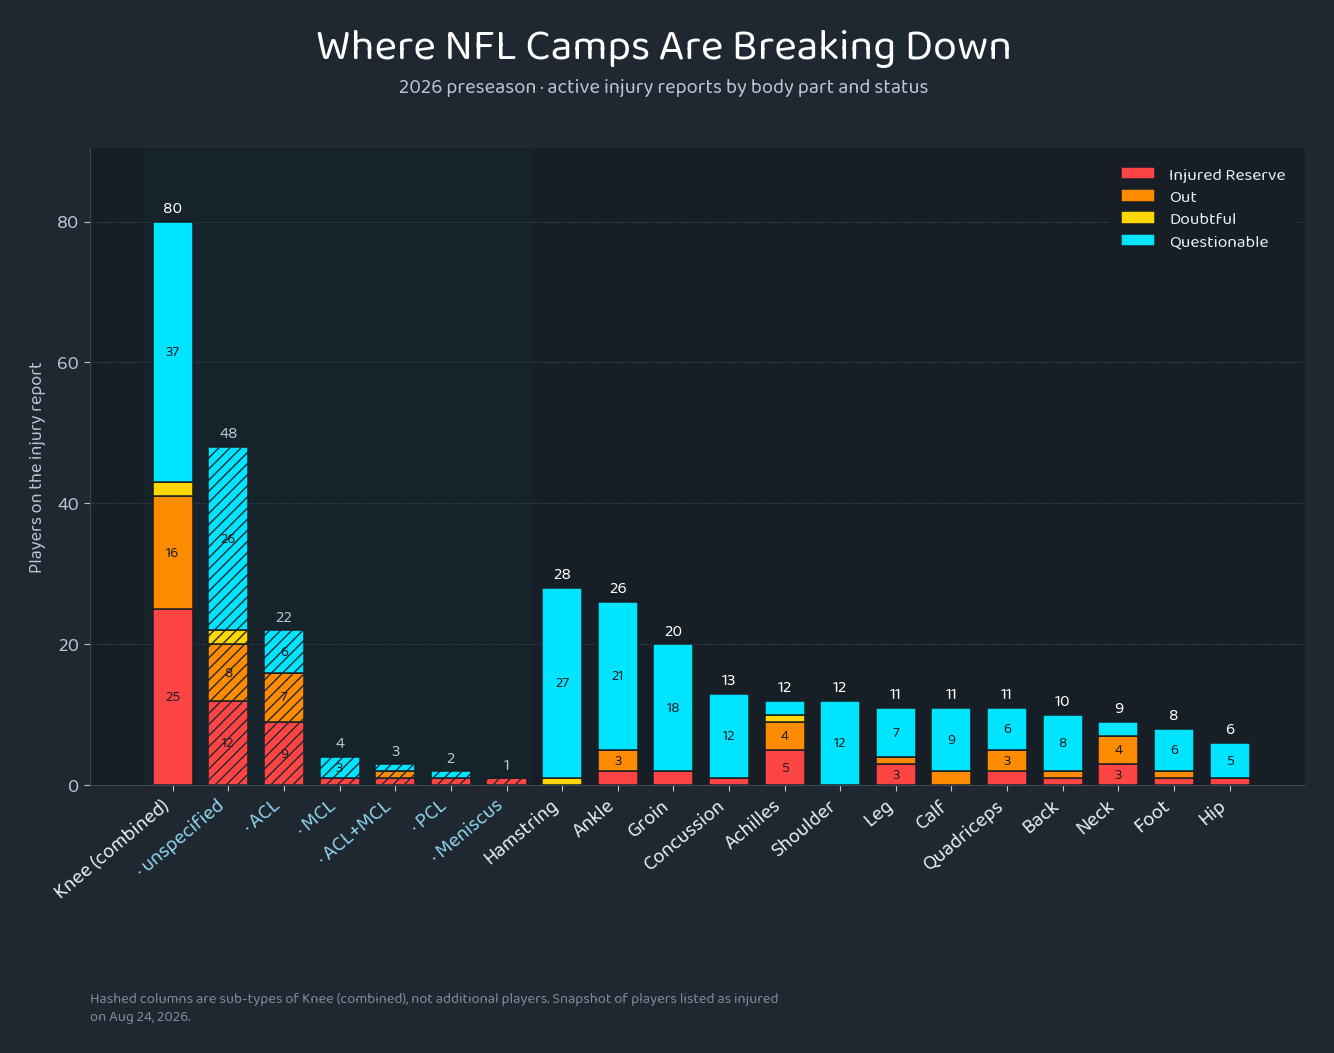

In [13]:
fig.text(
    0.075,
    0.035,
    "Hashed columns are sub-types of Knee (combined), not additional players. "
    "Snapshot of players listed as injured\non Aug 24, 2026. ",
    ha="left",
    va="bottom",
    fontsize=10.5,
    color="#7C8B99",
    linespacing=1.5,
)

fig

## Step 11 — Save

`pad_inches=0` keeps the 1350 x 1080 canvas exactly as laid out.

In [14]:
out = FIGURES_DIR / "injury_status_by_type.png"
out.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(out, dpi=100, pad_inches=0)
print(f"saved -> {out.name}  ({out.stat().st_size / 1024:.0f} KB)")

saved -> injury_status_by_type.png  (120 KB)


---

### Column totals for reference

In [15]:
list(zip(labels, bottom))

[('Knee (combined)', 80),
 ('· unspecified', 48),
 ('· ACL', 22),
 ('· MCL', 4),
 ('· ACL+MCL', 3),
 ('· PCL', 2),
 ('· Meniscus', 1),
 ('Hamstring', 28),
 ('Ankle', 26),
 ('Groin', 20),
 ('Concussion', 13),
 ('Achilles', 12),
 ('Shoulder', 12),
 ('Leg', 11),
 ('Calf', 11),
 ('Quadriceps', 11),
 ('Back', 10),
 ('Neck', 9),
 ('Foot', 8),
 ('Hip', 6)]